# **Práctica 2**

In [1]:
from qiskit import QuantumRegister, QuantumCircuit, generate_preset_pass_manager
from qiskit import transpile
from qiskit_aer import AerSimulator
# from qiskit.visualization import plot_bloch_multivector, plot_histogram
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from qiskit_aer import AerSimulator
from qiskit.circuit.library import *
from qiskit.circuit import Gate

import numpy as np
# Importing standard Qiskit libraries
from qiskit.visualization import *

from qiskit.quantum_info import Statevector, Pauli, Operator

from tabulate import tabulate

from functools import reduce
import matplotlib.pyplot as plt
import matplotlib
from PIL import Image
import io
import random
from scipy.stats import chisquare, chi2

#%matplotlib inline

In [2]:
seed = 98
shots = 4096
np.random.seed(seed)
random.seed(seed)

## **Bloque 3: Algoritmos de consulta: Deutsch, Deutsch-Jozsa y Bernstein-Vazirani**

### **Ejercicio 3.1: Algoritmo de Deutsch**

In [3]:
def oraculo(qc, tipo):
    if tipo == "a":          # f(x) = 0 -> identidad
        pass
    elif tipo == "b":        # f(x) = 1 -> X sobre la ancilla
        qc.x(1)
    elif tipo == "c":        # f(x) = x -> CNOT
        qc.cx(0, 1)
    elif tipo == "d":        # f(x) = NOT x -> CNOT + X
        qc.cx(0, 1)
        qc.x(1)

def deutsch(tipo):
    qc = QuantumCircuit(2, 1)
    qc.x(1)                  # ancilla en |1>
    qc.h([0, 1])
    qc.barrier()
    oraculo(qc, tipo)
    qc.barrier()
    qc.h(0)
    qc.measure(0, 0)
    return qc

sim = AerSimulator()
deutsch_qcs = {}
for t in "abcd":
    qc = deutsch(t)
    deutsch_qcs[t] = qc

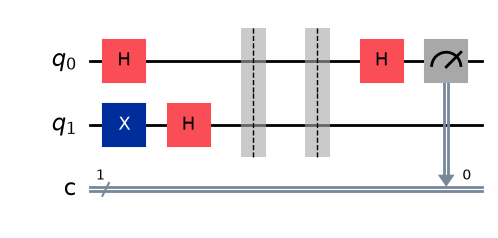

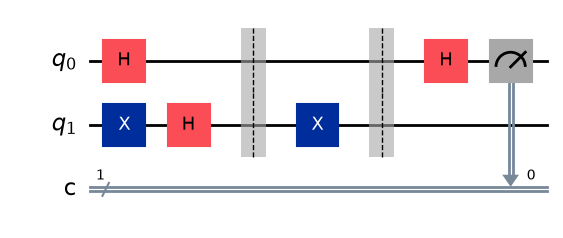

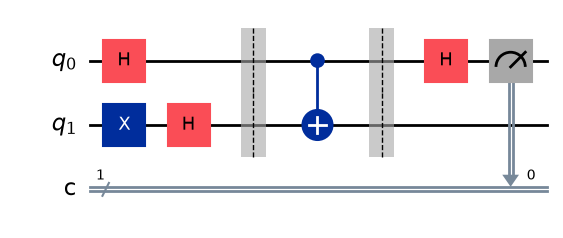

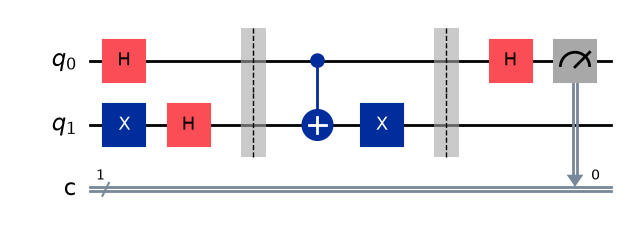

In [4]:
for qc in deutsch_qcs.values():
    display(qc.draw('mpl'))

**Simulación**

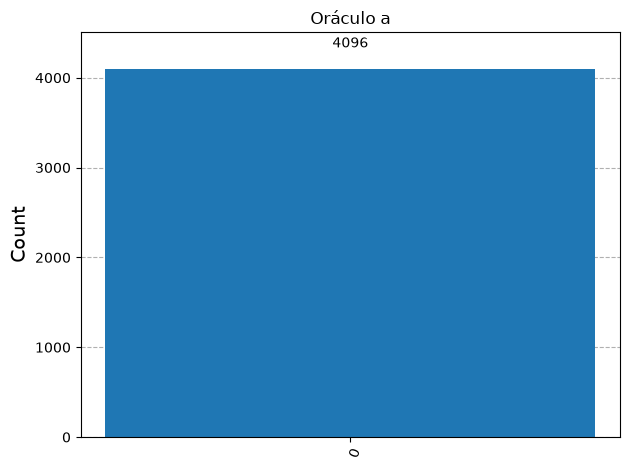

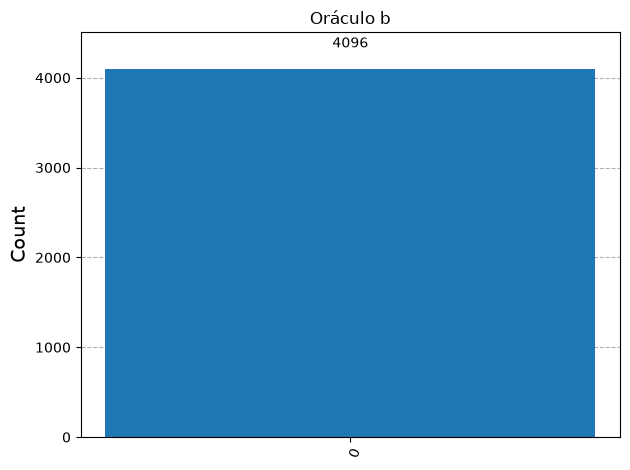

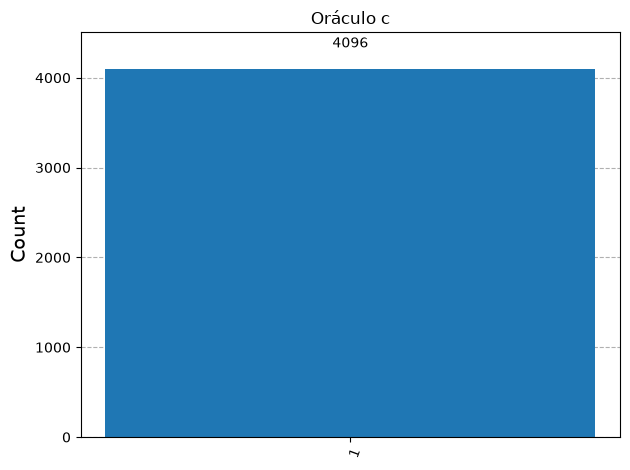

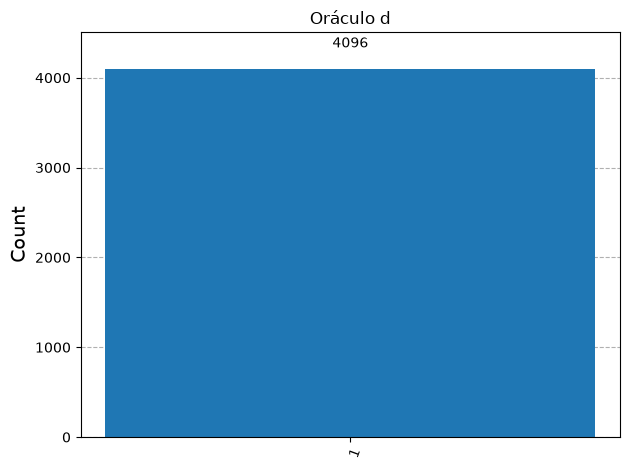

In [5]:
for nombre, qc in deutsch_qcs.items():
    counts = sim.run(transpile(qc, sim), shots=shots).result().get_counts()
    fig = plot_histogram(counts, title=f"Oráculo {nombre}")
    display(fig)

### **Ejercicio 3.2: Deutsch-Jozsa con $n=2$**

In [6]:
def oraculos3_2(tipo):
    qc = QuantumCircuit(3, name = f'oraculo {tipo}')
    if tipo == "a":
        pass
    elif tipo == "b":
        qc.cx(0, 2)
        qc.cx(1, 2)
    else: #apartado c)
        qc.ccx(0, 1, 2)
    display(qc.draw('mpl'))
    return qc.to_gate()

def deutsch_jozsa(oraculo, n = 2):
    qc = QuantumCircuit(n + 1, n)
    qc.x(n)
    qc.h(range(n + 1))
    
    qc.append(oraculo, range(n + 1))
    qc.h(range(n + 1))
    qc.measure(range(n), range(n))
    return qc


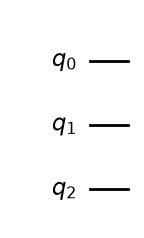

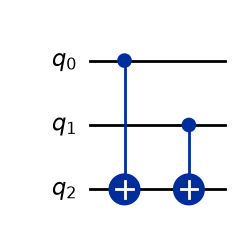

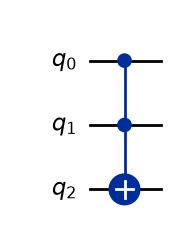

In [7]:
djcircuits = {}
for t in "abc":
    qc = deutsch_jozsa(oraculos3_2(t), 2)
    djcircuits[t] = qc
    qc.draw('mpl')

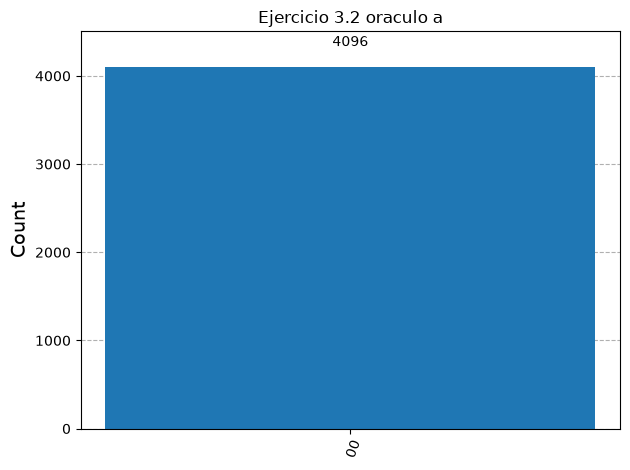

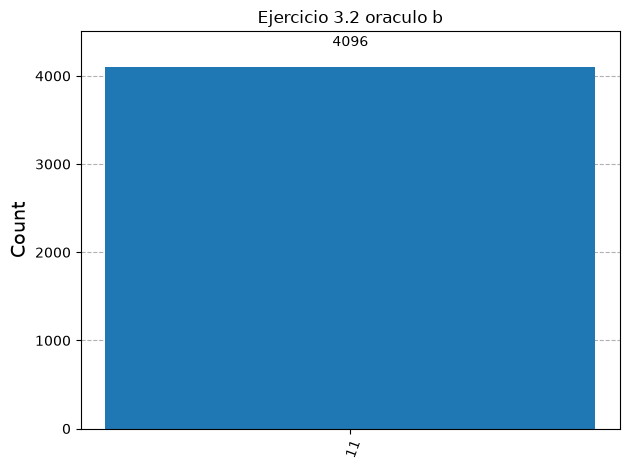

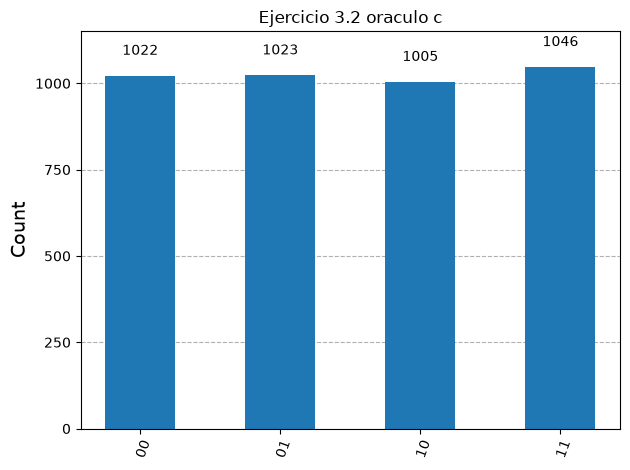

In [8]:
for nombre, qc in djcircuits.items():
    counts = sim.run(transpile(qc, sim), shots=shots).result().get_counts()
    fig = plot_histogram(counts, title=f"Ejercicio 3.2 oraculo {nombre}")
    display(fig)

### **Ejercicio 3.3: Bernstein-Vazirani**

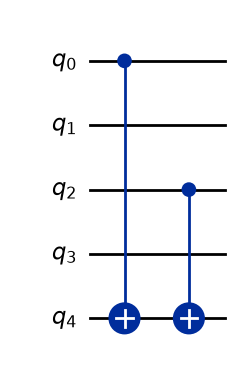

In [9]:
#Construyo oraculo para clave oculta a = 1010
oraculo_a1 = QuantumCircuit(5, name = "oraculo_a1")
oraculo_a1.cx(0, 4)
oraculo_a1.cx(2, 4)
display(oraculo_a1.draw('mpl'))
oraculoa1_gate = oraculo_a1.to_gate()

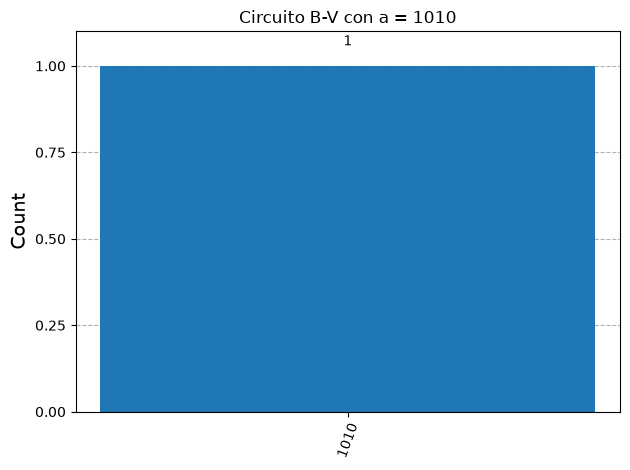

In [10]:
bvazirani_a1 = QuantumCircuit(5, 4, name = "circuito_bernstein_vazirani")
bvazirani_a1.x(4)
bvazirani_a1.h(range(5))
bvazirani_a1.barrier()
bvazirani_a1.append(oraculoa1_gate, range(5))
bvazirani_a1.barrier()
bvazirani_a1.h(range(5))
bvazirani_a1.measure(range(4), range(3, -1, -1)) #Invierto los bits de medida

counts = sim.run(transpile(bvazirani_a1, sim), shots=1).result().get_counts()
fig = plot_histogram(counts, title=f"Circuito B-V con a = 1010")
display(fig)

**Probar otra clave $a = 1101$**

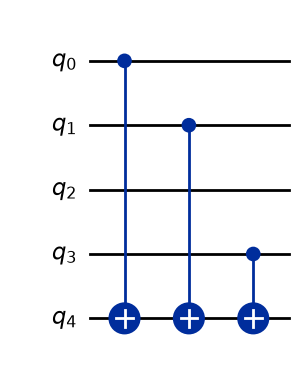

In [11]:
#Construyo oraculo para clave oculta a = 1101
oraculo_a2 = QuantumCircuit(5, name = "oraculo_a2")
oraculo_a2.cx(0, 4)
oraculo_a2.cx(1, 4)
oraculo_a2.cx(3, 4)
display(oraculo_a2.draw('mpl'))

oraculoa2_gate = oraculo_a2.to_gate()

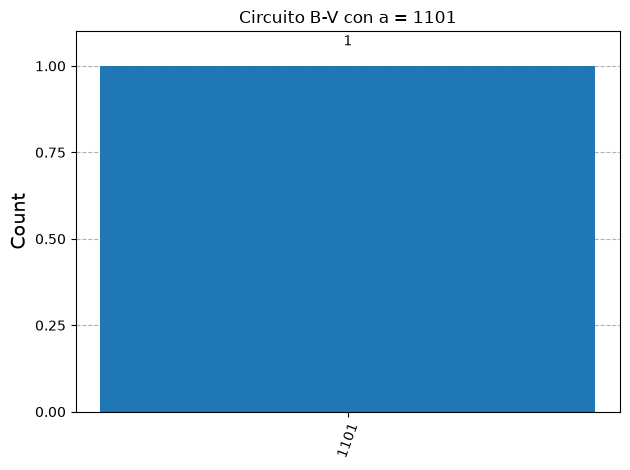

In [12]:
bvazirani_a2 = QuantumCircuit(5, 4, name = "circuito_bernstein_vazirani_a2")
bvazirani_a2.x(4)
bvazirani_a2.h(range(5))
bvazirani_a2.barrier()
bvazirani_a2.append(oraculoa2_gate, range(5))
bvazirani_a2.barrier()
bvazirani_a2.h(range(5))
bvazirani_a2.measure(range(4), range(3, -1, -1)) #Invierto los bits de medida

counts = sim.run(transpile(bvazirani_a2, sim), shots=1).result().get_counts()
fig = plot_histogram(counts, title=f"Circuito B-V con a = 1101")
display(fig)

### **Ejercicio E1: Deutsch-Jozsa con un oraculo dado**

**Implementación del circuito y simulacion**

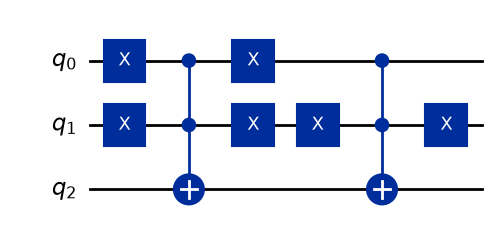

In [13]:
# Construyo el oraculo
dj_f = QuantumCircuit(3, name = "DJ_F")
dj_f.x([0, 1])
dj_f.ccx(0, 1, 2)
dj_f.x([0, 1])

dj_f.x(1)
dj_f.ccx(0, 1, 2)
dj_f.x(1)
display(dj_f.draw('mpl'))

oraculo_djf = dj_f.to_gate()

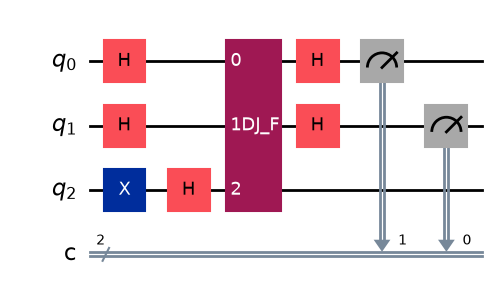

In [14]:
# Implemento el circuito
e1dj = QuantumCircuit(3, 2)
e1dj.x(2)
e1dj.h([0, 1, 2])
e1dj.append(oraculo_djf, [0, 1, 2])
e1dj.h([0, 1])

e1dj.measure([0, 1], [1, 0])
e1dj.draw('mpl')

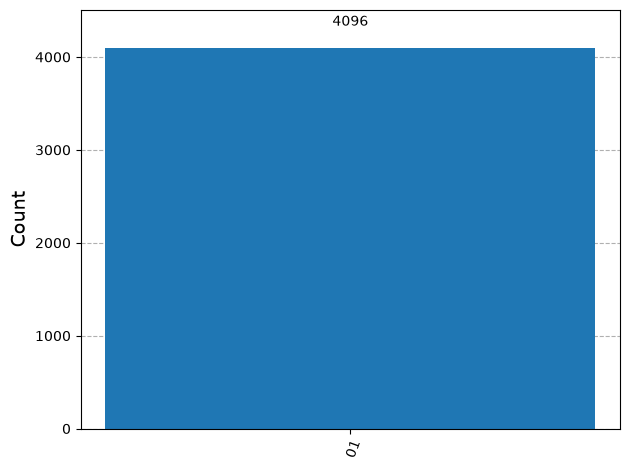

In [15]:
counts = sim.run(transpile(e1dj, sim), shots = shots).result().get_counts()
plot_histogram(counts)

**Determinar la función $f: \{0, 1\}² \rightarrow \{0, 1\}$**

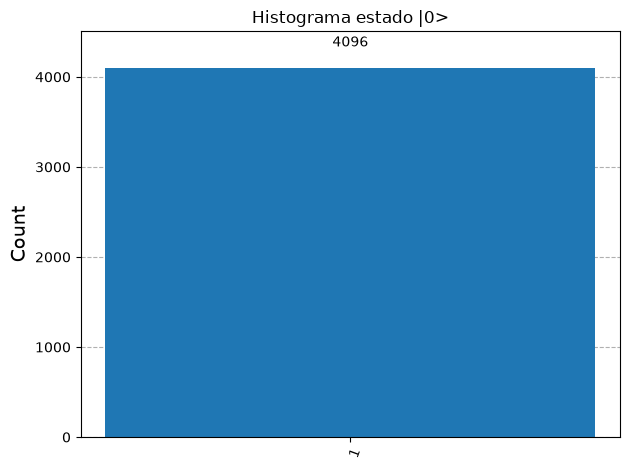

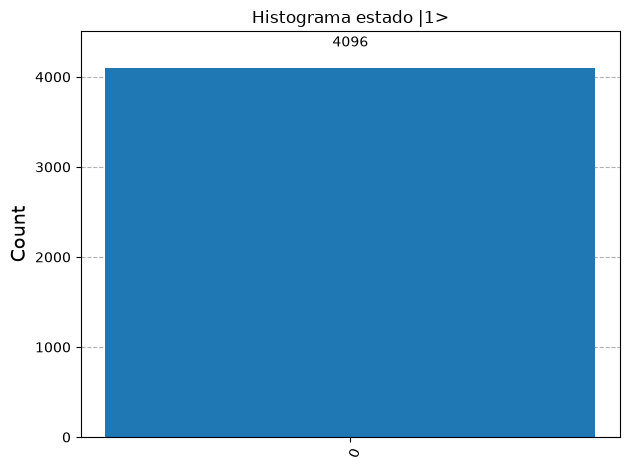

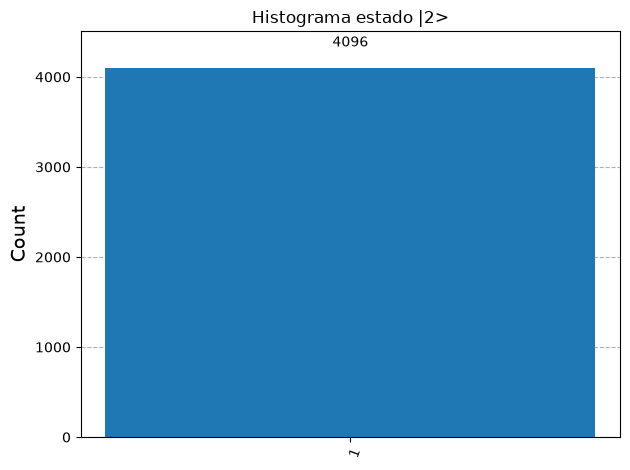

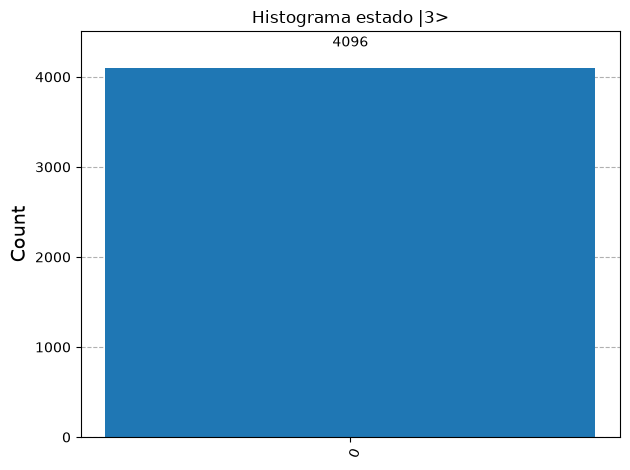

In [16]:
def init_circuit (qc, valor):
    if valor == 0:
        pass
    elif valor == 1:
        qc.x(1)
    elif valor == 2:
        qc.x(0)
    else:
        qc.x([0, 1])

for i in range(4):
    qc = QuantumCircuit(3, 1)
    init_circuit(qc, i)
    qc.append(oraculo_djf, [0, 1, 2])
    qc.measure(2, 0)
    #print(qc)

    counts = sim.run(transpile(qc, sim), shots = shots).result().get_counts()
    display(plot_histogram(counts, title = f'Histograma estado |{i}>'))

## **Bloque 5: Estimación cuántica de fase (QPE)**

### **Ejercicio 5.1. Fase exacta: puerta S**

In [17]:
# En esta sección se usara el PhaseGate() de Qiskit
u = PhaseGate(np.pi/2) # Theta = 1/4
t = 2

In [18]:
def qpe_circuit(t, gate: Gate):
    cgate = gate.control(1)
    qc = QuantumCircuit(t + 1, t,  name = f'Circuito QPE')
    qc.h(range(t))
    qc.x(t)
    for i in range(t - 1, -1, -1):
        times = 2**i
        for _ in range(times):
            qc.append(cgate, [i, t])
    qc.append(QFTGate(t).inverse(), range(t))
    qc.measure(range(t), range(t))
    return qc

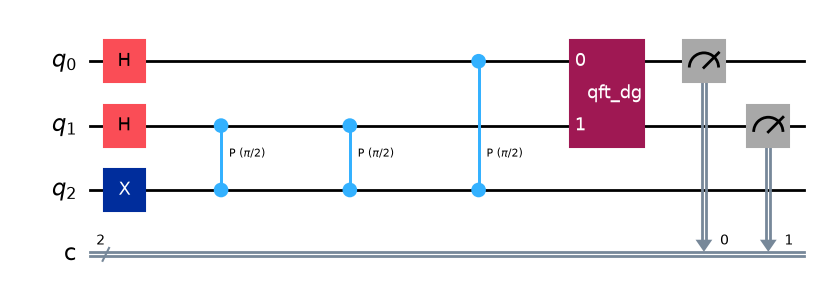

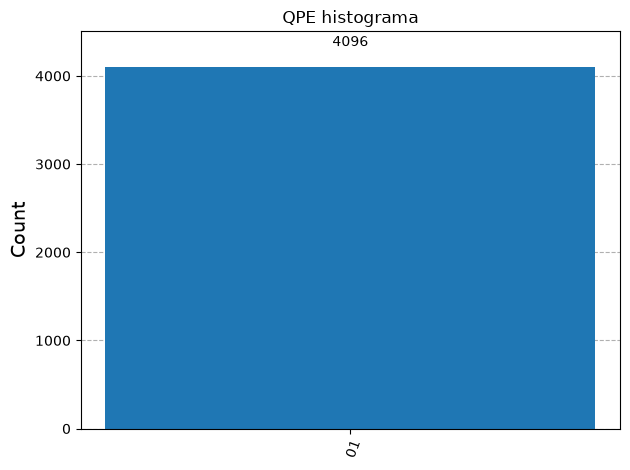

In [19]:
qc = qpe_circuit(t, u)
display(qc.draw('mpl'))
counts = sim.run(transpile(qc, sim), shots = shots).result().get_counts()
plot_histogram(counts, title = fr'QPE histograma')

### **Ejercicio 5.2. Fase no exacta con pocos qubits**

In [20]:
t = 2
u1 = PhaseGate(4*np.pi/5)
u2 = PhaseGate(6*np.pi/32)

In [21]:
def get_probs(counts, shots):
    probs = {}
    for k, v in counts.items():
        probs[k] = v/shots

    return probs

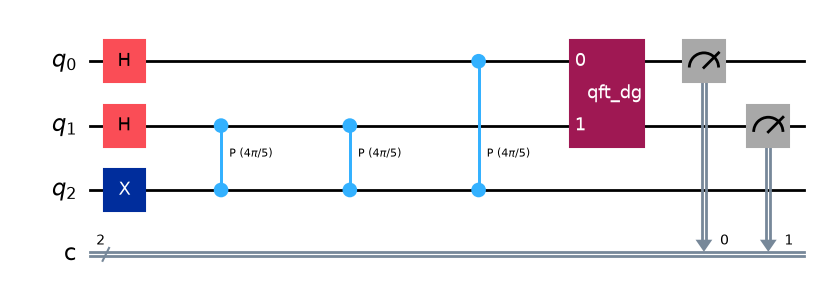

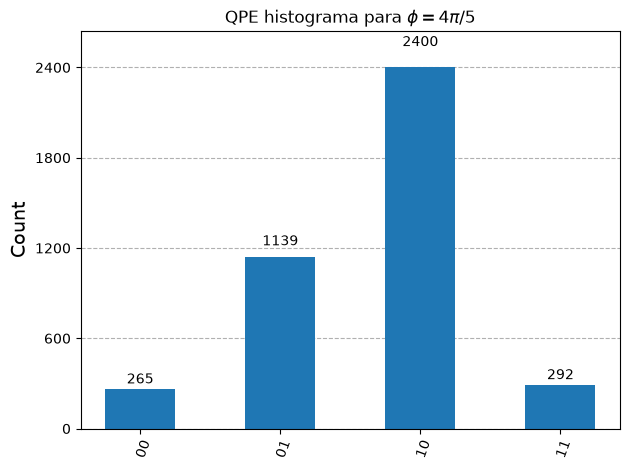

In [22]:
qc = qpe_circuit(t, u1)
display(qc.draw('mpl'))
counts = sim.run(transpile(qc, sim), shots = shots).result().get_counts()
plot_histogram(counts, title = fr'QPE histograma para $\phi = 4\pi/5$')

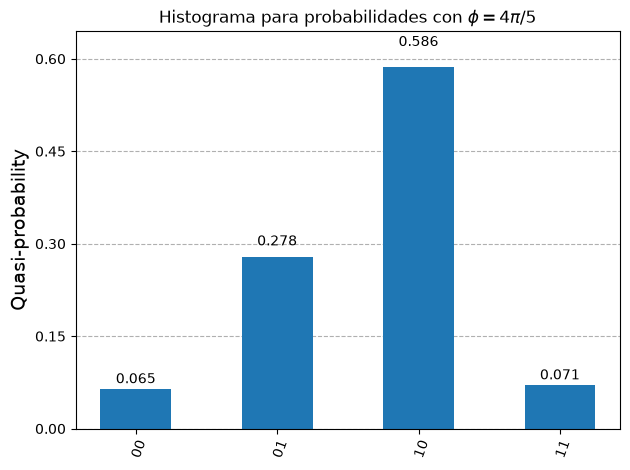

In [23]:
cprobs = get_probs(counts, shots)
plot_histogram(cprobs, title = fr'Histograma para probabilidades con $\phi = 4\pi/5$')

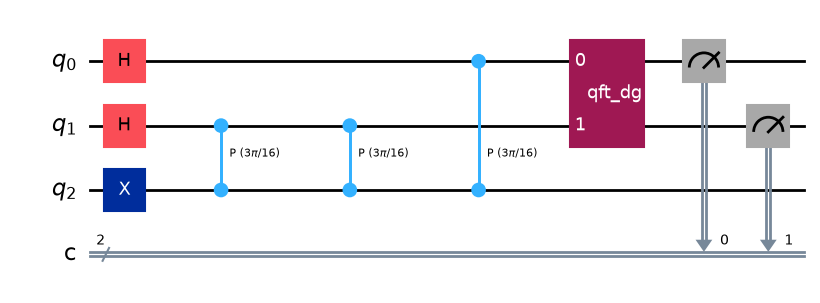

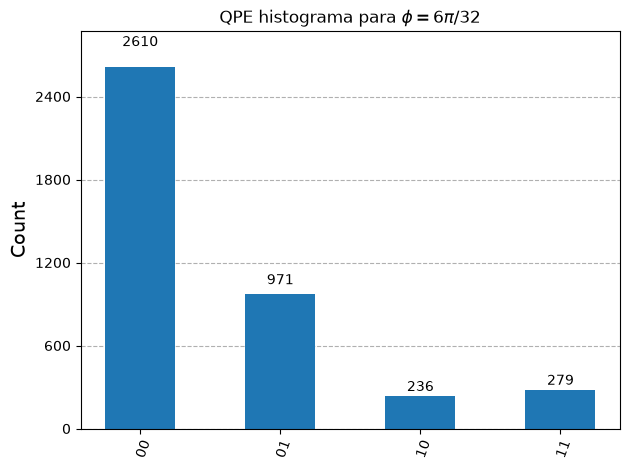

In [24]:
qc = qpe_circuit(t, u2)
display(qc.draw('mpl'))
counts = sim.run(transpile(qc, sim), shots = shots).result().get_counts()
plot_histogram(counts, title = fr'QPE histograma para $\phi = 6\pi/32$')

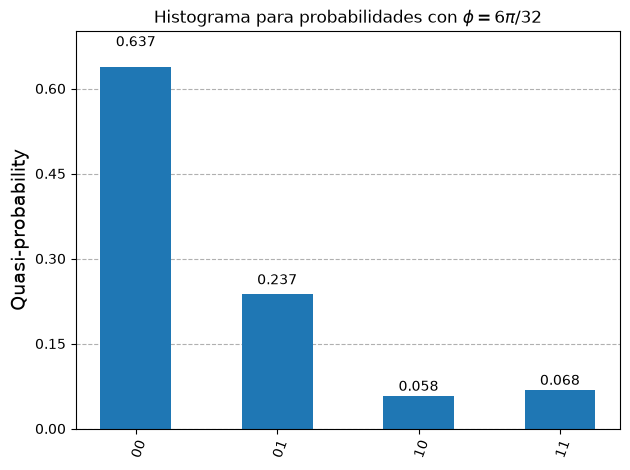

In [25]:
cprobs = get_probs(counts, shots)
plot_histogram(cprobs, title = fr'Histograma para probabilidades con $\phi = 6\pi/32$')

### **Ejercicio 5.3. Aumento del número de qubits de conteo**

In [26]:
t = 5

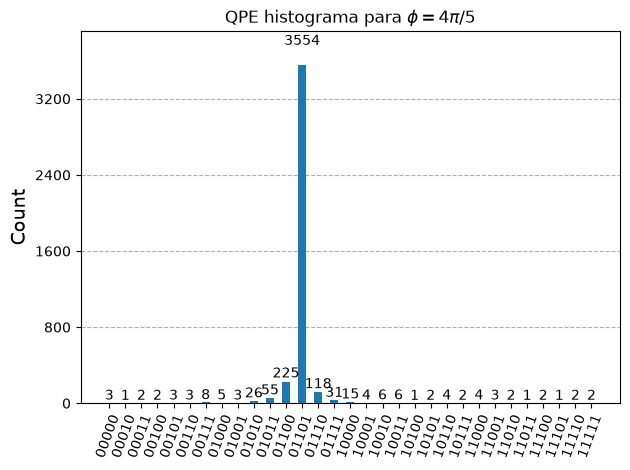

In [27]:
qc = qpe_circuit(t, u1)
counts = sim.run(transpile(qc, sim), shots = shots).result().get_counts()
plot_histogram(counts, title = fr'QPE histograma para $\phi = 4\pi/5$')

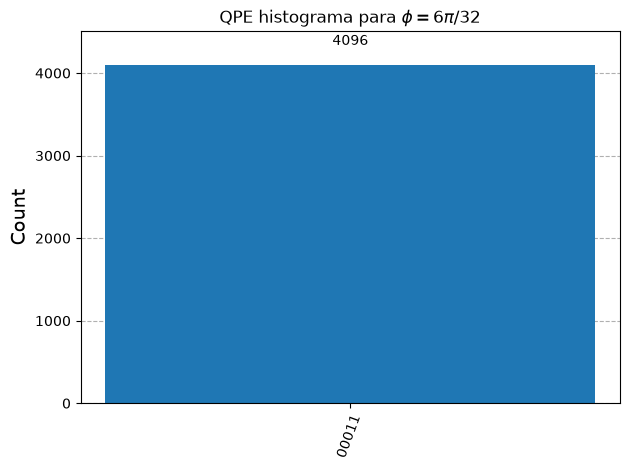

In [28]:
qc = qpe_circuit(t, u2)
counts = sim.run(transpile(qc, sim), shots = shots).result().get_counts()
plot_histogram(counts, title = fr'QPE histograma para $\phi = 6\pi/32$')

### **Ejercicio E2.1. QPE con $t = 3$ para $U = P(2\pi/3)$**

In [29]:
t = 3
u = PhaseGate(2*np.pi/3)

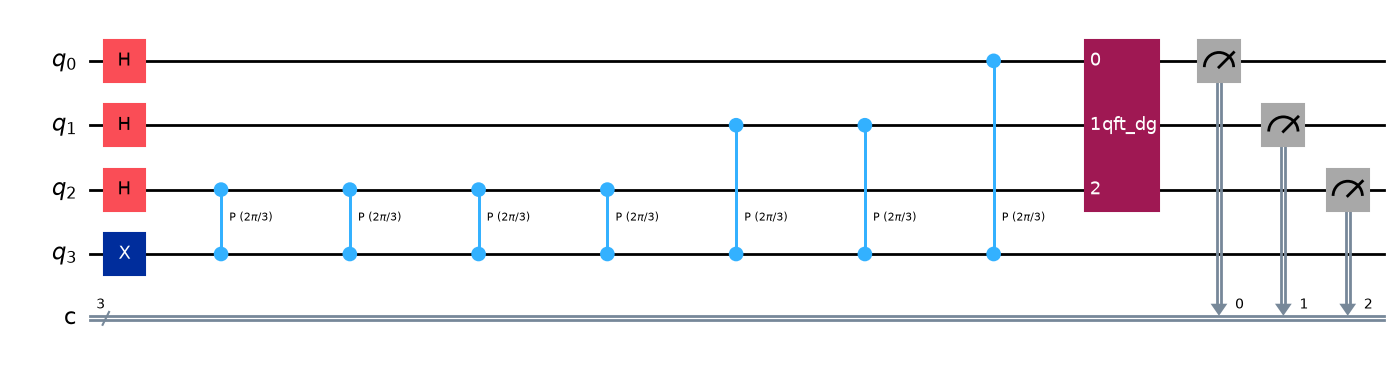

In [30]:
#Apartados a), b)
cu = u.control(1)
qc = QuantumCircuit(t + 1, t, name = f'Circuito QPE')
qc.x(t) # Preparo el estado |1> que es un autovector

qc.h(range(t))
point1 = Statevector(qc)

for i in range(t - 1, -1, -1):
    times = 2**i
    for _ in range(times):
        qc.append(cu, [i, t])
point2 = Statevector(qc)

qc.append(QFTGate(t).inverse(), range(t))
point3 = Statevector(qc)
qc.measure(range(t), range(t))
display(qc.draw('mpl'))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

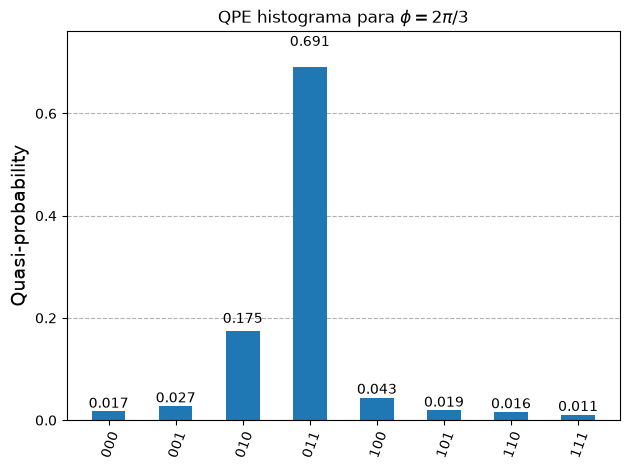

In [31]:
display(point1.draw("latex"))
display(point2.draw("latex"))
display(point3.draw("latex"))

counts = sim.run(transpile(qc, sim), shots = shots).result().get_counts()
plot_histogram(get_probs(counts, shots), title = fr'QPE histograma para $\phi = 2\pi/3$')

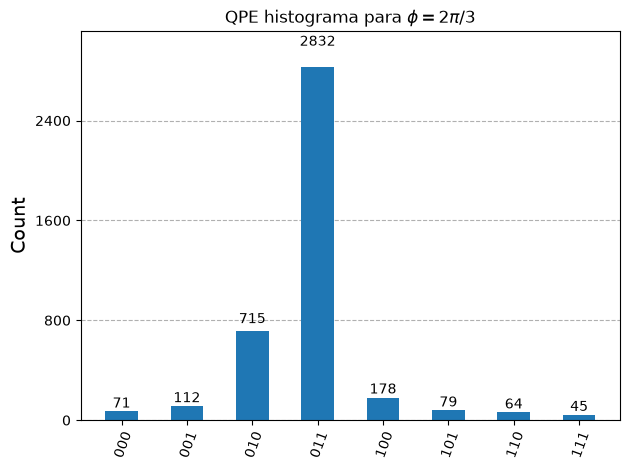

In [32]:
plot_histogram(counts, title = fr'QPE histograma para $\phi = 2\pi/3$')

### **Ejercicio E2.2. Mejora de la precisión**

In [33]:
ts = [i for i in range(4, 16)]
u = PhaseGate(2*np.pi/3)
cu = u.control(1)
theta = 1/3

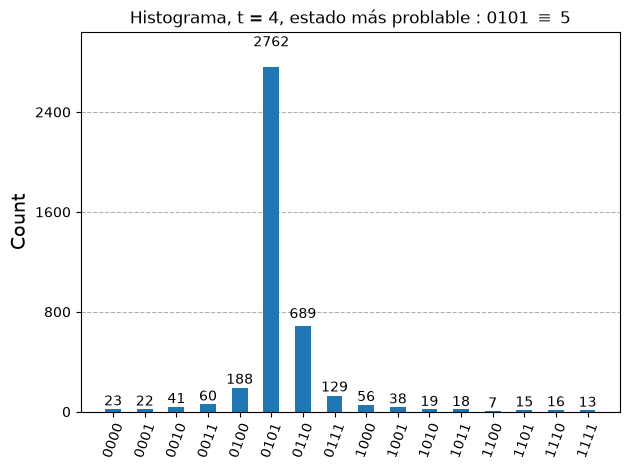

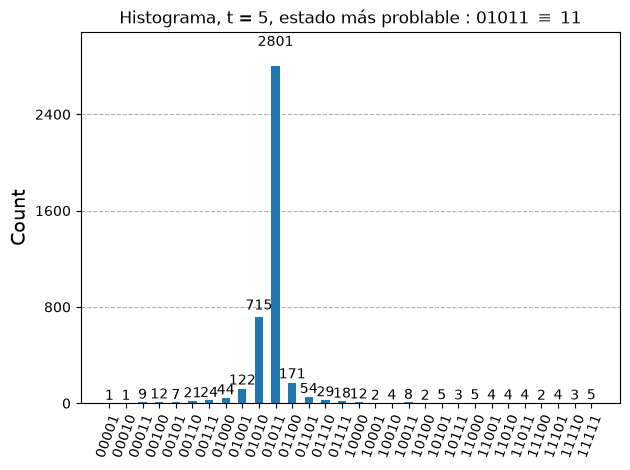

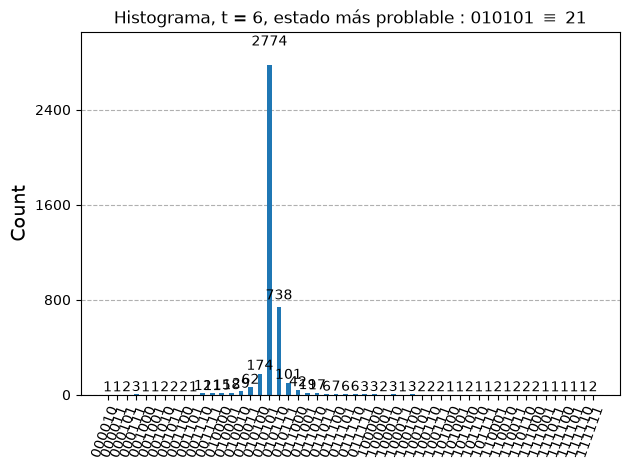

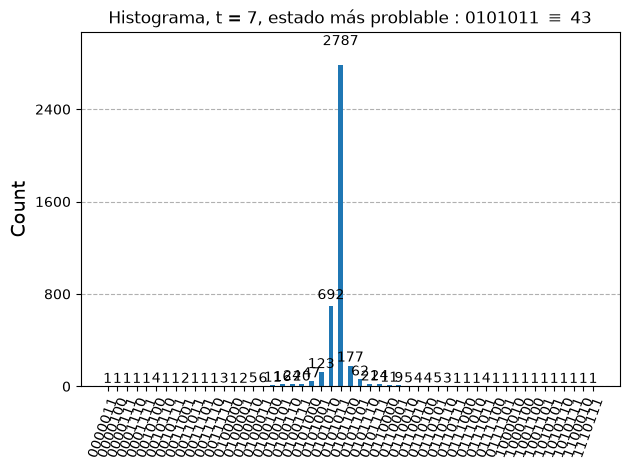

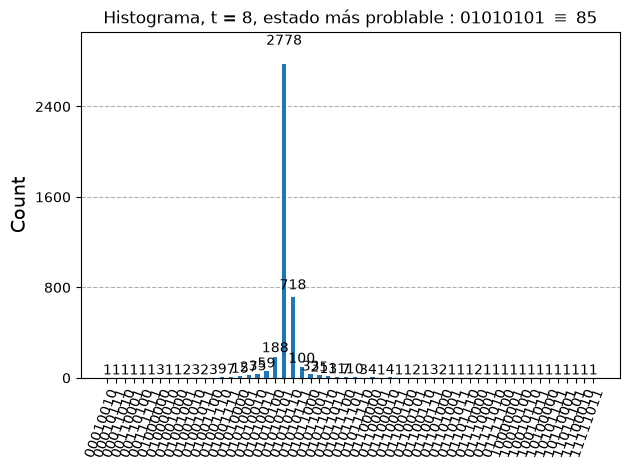

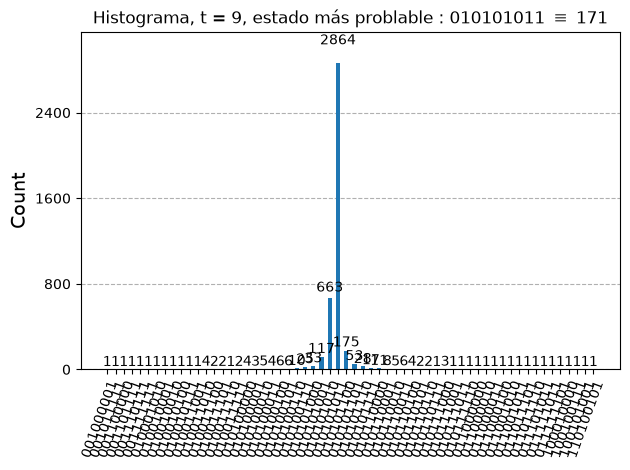

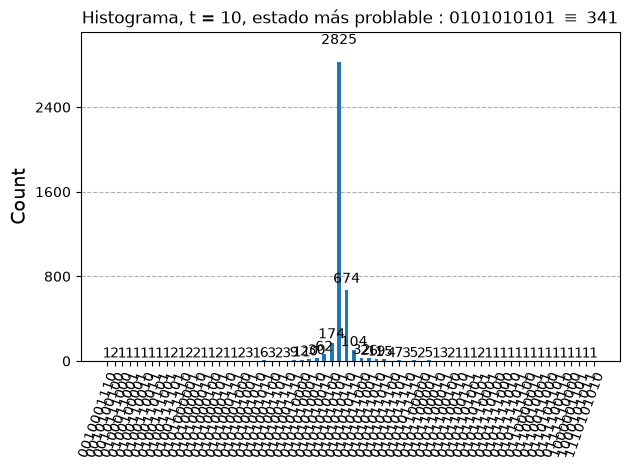

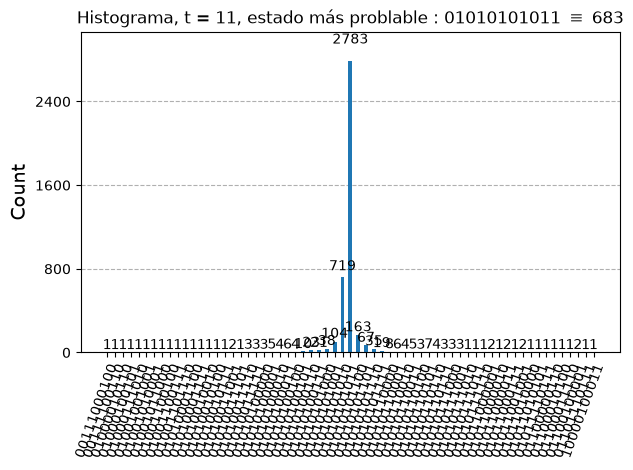

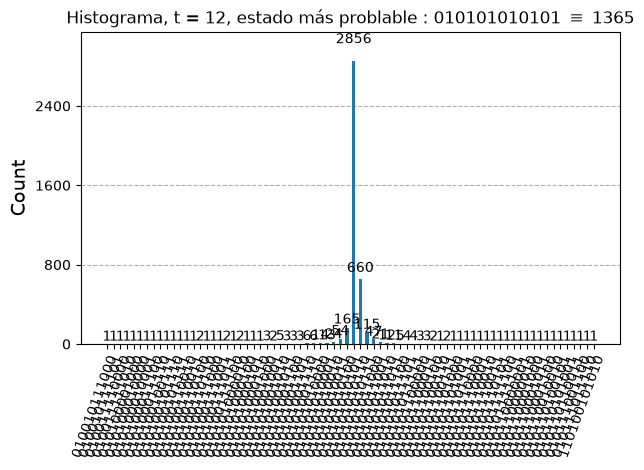

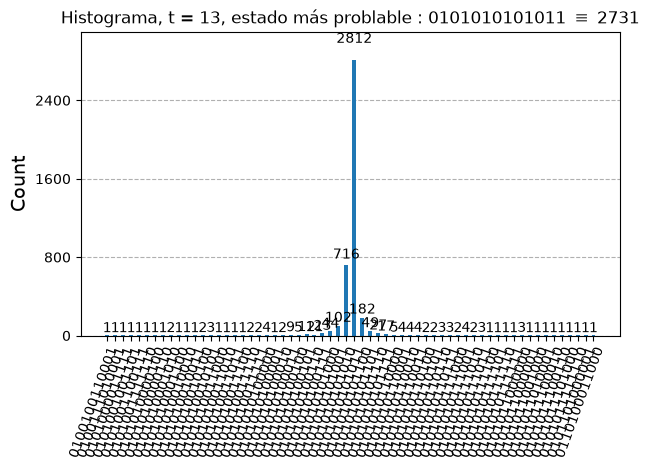

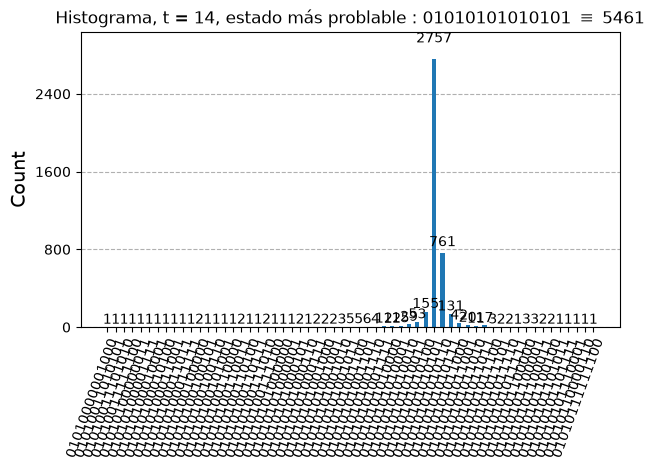

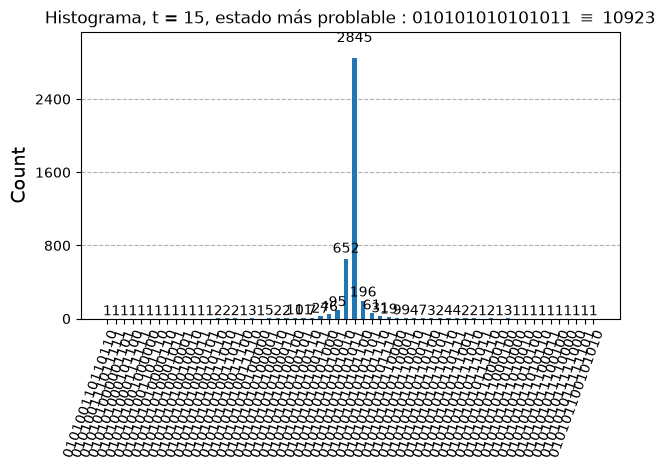

In [34]:
maxm = {}
thetas = {}
probs = {}
abs_errors= {}
for t in ts: 
    qc = qpe_circuit(t, u)
    counts = sim.run(transpile(qc, sim), shots = shots).result().get_counts()
    m = max(counts, key = counts.get)
    maxm[t] = m
    thetas[t] = int(m, 2)/(2**t)
    abs_errors[t] = abs(theta - int(m, 2)/(2**t)) 
    probs[t] = counts[m]/shots
    display(plot_histogram(counts, title = fr'Histograma, t = {t}, estado más problable : {m} $\equiv$ {int(m, 2)}'))

In [35]:
print(maxm)
print(probs)
print(thetas)
print(abs_errors)

{4: '0101', 5: '01011', 6: '010101', 7: '0101011', 8: '01010101', 9: '010101011', 10: '0101010101', 11: '01010101011', 12: '010101010101', 13: '0101010101011', 14: '01010101010101', 15: '010101010101011'}
{4: 0.67431640625, 5: 0.683837890625, 6: 0.67724609375, 7: 0.680419921875, 8: 0.67822265625, 9: 0.69921875, 10: 0.689697265625, 11: 0.679443359375, 12: 0.697265625, 13: 0.6865234375, 14: 0.673095703125, 15: 0.694580078125}
{4: 0.3125, 5: 0.34375, 6: 0.328125, 7: 0.3359375, 8: 0.33203125, 9: 0.333984375, 10: 0.3330078125, 11: 0.33349609375, 12: 0.333251953125, 13: 0.3333740234375, 14: 0.33331298828125, 15: 0.333343505859375}
{4: 0.020833333333333315, 5: 0.010416666666666685, 6: 0.005208333333333315, 7: 0.002604166666666685, 8: 0.0013020833333333148, 9: 0.0006510416666666852, 10: 0.00032552083333331483, 11: 0.00016276041666668517, 12: 8.138020833331483e-05, 13: 4.069010416668517e-05, 14: 2.034505208331483e-05, 15: 1.017252604168517e-05}


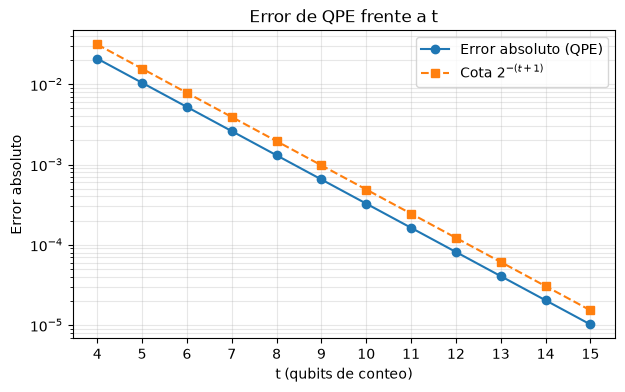

True


In [36]:
ts = sorted(abs_errors)                          # errores = {t: error_abs}
err = [abs_errors[t] for t in ts]
cota = [2**-(t + 1) for t in ts]

plt.figure(figsize=(7, 4))
plt.semilogy(ts, err, "o-", label="Error absoluto (QPE)")
plt.semilogy(ts, cota, "s--", label=r"Cota $2^{-(t+1)}$")
plt.xlabel("t (qubits de conteo)")
plt.ylabel("Error absoluto")
plt.xticks(ts)
plt.title("Error de QPE frente a t")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

# Comprobación numérica de la cota
print(all(e <= c + 1e-12 for e, c in zip(err, cota)))

### **Ejercicio E2.3. Operador diagonal con dos fases**

In [37]:
phi0 = 0.275
phi1 = 0.375
t = 6

In [38]:
def c_U_gate(phi0, phi1, power):
    """Puerta controlada de U^power, U = diag(e^{2πi·phi0}, e^{2πi·phi1})."""
    U = QuantumCircuit(1)
    for _ in range(power):
        U.rz(-phi0 * 4 * np.pi, 0)
        U.p((phi1 + phi0) * 2 * np.pi, 0)
    U = U.to_gate()
    U.name = "U(%.3f, %.3f)^%i" % (phi0, phi1, power)
    return U.control()
# En QPE, el qubit de conteo j controla U^(2^j):
# qc.append(c_U_gate(phi0, phi1, 2**j), [j, t])

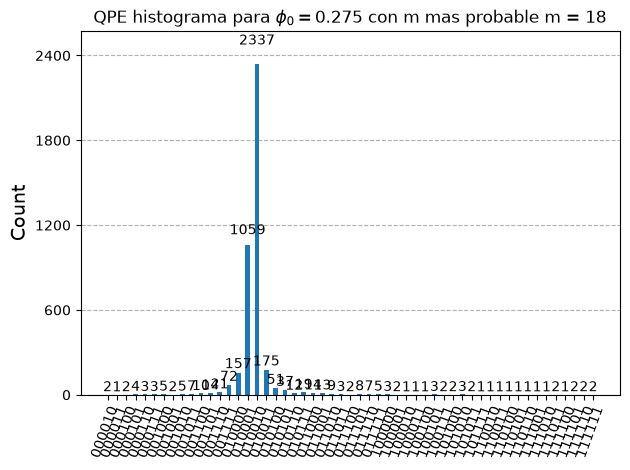

Fase estimada = 0.28125 con error = 0.006249999999999978


In [39]:
# Autovector |0>
qc0 = QuantumCircuit(t + 1, t)

qc0.h(range(t))

for i in range(t - 1, -1, -1):
    qc0.append(c_U_gate(phi0, phi1, 2**i), [i, t])

qc0.append(QFTGate(t).inverse(), range(t))

qc0.measure(range(t), range(t))
#display(qc0.draw('mpl'))
counts = sim.run(transpile(qc0, sim), shots = shots).result().get_counts()
m0 = max(counts, key = counts.get)
display(plot_histogram(counts, title = fr'QPE histograma para $\phi_0 = 0.275$ con m mas probable m = {int(m0, 2)}'))
estimated_phase0 = int(m0, 2)/2**t
error0 = abs(phi0 - estimated_phase0)
print(fr'Fase estimada = {estimated_phase0} con error = {error0}')


011000


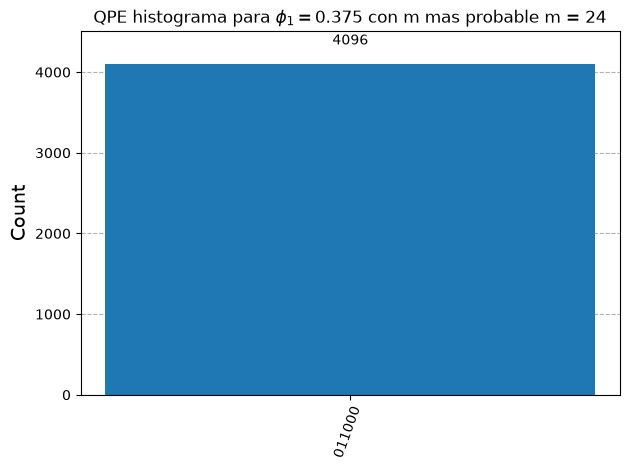

Fase estimada = 0.375 con error = 0.0


In [40]:
# Autovector |1>
qc1 = QuantumCircuit(t + 1, t)
qc1.x(t) # Preparo el autovector |1> en el qubit t

qc1.h(range(t))

for i in range(t - 1, -1, -1):
    qc1.append(c_U_gate(phi0, phi1, 2**i), [i, t])

qc1.append(QFTGate(t).inverse(), range(t))

qc1.measure(range(t), range(t))
#display(qc1.draw('mpl'))
counts = sim.run(transpile(qc1, sim), shots = shots).result().get_counts()
m1 = max(counts, key = counts.get)
print(m1)
display(plot_histogram(counts, title = fr'QPE histograma para $\phi_1 = 0.375$ con m mas probable m = {int(m1, 2)}'))
estimated_phase1 = int(m1, 2)/2**t
error1 = abs(phi1 - estimated_phase1)
print(fr'Fase estimada = {estimated_phase1} con error = {error1}')

### **Ejerciciio E2.4. Combinación lineal de autovectores**

In [41]:
phi0 = 0.275
phi1 = 0.375
t = 6

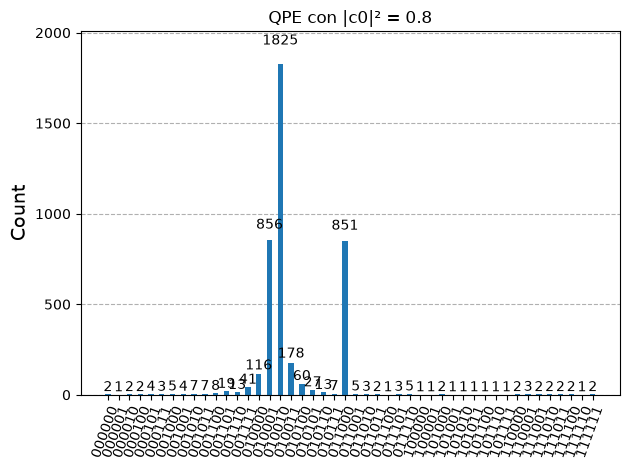

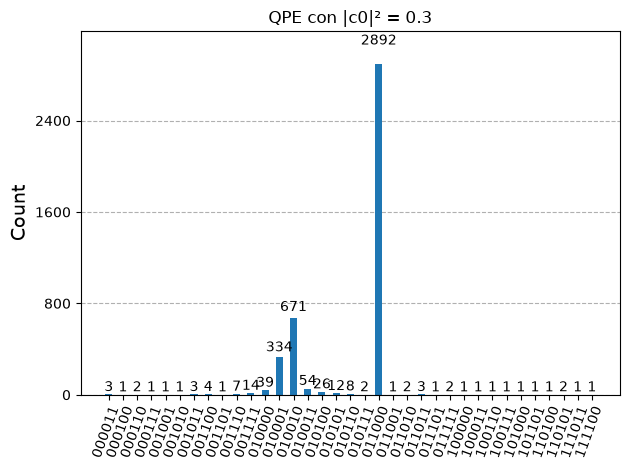

In [42]:
def qpe_psi(p0, medir_psi=False):
    theta = 2 * np.arccos(np.sqrt(p0))
    qc = QuantumCircuit(t + 1, t + 1 if medir_psi else t)
    qc.ry(theta, t)                    # |psi> = c0|0> + c1|1> en el qubit t
    qc.h(range(t))
    for i in range(t):
        qc.append(c_U_gate(phi0, phi1, 2**i), [i, t])   # tu c_U_gate del E2.3
    qc.append(QFTGate(t).inverse(), range(t))
    qc.measure(range(t), range(t))
    if medir_psi:
        qc.measure(t, t)               # para el apartado c)
    return qc

for p0 in (0.8, 0.3):
    counts = sim.run(transpile(qpe_psi(p0), sim), shots=shots).result().get_counts()
    display(plot_histogram(counts, title=f"QPE con |c0|² = {p0}"))

In [43]:
def prob_qpe(m, phi):
    k = np.arange(2**t)
    amp = np.exp(2j * np.pi * k * (phi - m / 2**t)).sum() / 2**t
    return abs(amp) ** 2

def prediccion(p0):
    return {format(m, f"0{t}b"): p0 * prob_qpe(m, phi0) + (1 - p0) * prob_qpe(m, phi1)
            for m in range(2**t)}

p0 = 0.8
counts = sim.run(transpile(qpe_psi(p0), sim), shots=shots).result().get_counts()
pred = prediccion(p0)
for m in (17, 18, 24):
    s = format(m, f"0{t}b")
    print(f"m={m}: observado {counts.get(s, 0)/shots:.3f}, predicho {pred[s]:.3f}")

m=17: observado 0.194, predicho 0.204
m=18: observado 0.466, predicho 0.458
m=24: observado 0.208, predicho 0.202


In [44]:
p1 = 0.3
counts = sim.run(transpile(qpe_psi(p1), sim), shots=shots).result().get_counts()
pred = prediccion(p1)
for m in (17, 18, 24):
    s = format(m, f"0{t}b")
    print(f"m={m}: observado {counts.get(s, 0)/shots:.3f}, predicho {pred[s]:.3f}")

m=17: observado 0.079, predicho 0.076
m=18: observado 0.187, predicho 0.172
m=24: observado 0.681, predicho 0.701
